In [223]:
'''
Predict the price of the Uber ride from a given pickup point to the agreed drop-off location.
Perform following tasks:
1. Pre-process the dataset.
2. Identify outliers.
3. Check the correlation.
4. Implement linear regression and random forest regression models.
5. Evaluate the models and compare their respective scores like R2, RMSE,
'''


import pandas as pd
!pip install matplotlib
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

Defaulting to user installation because normal site-packages is not writeable


In [224]:
df = pd.read_csv("uber.csv")

In [225]:
df.head()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [226]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  str    
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  str    
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), str(2)
memory usage: 13.7 MB
None


In [227]:
print(df.isnull().sum())

Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64


In [228]:
df = df.dropna()

In [229]:
print(df.isnull().sum())

Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    0
dropoff_latitude     0
passenger_count      0
dtype: int64


In [230]:
# calculate distance using Euclidean formula
df['distance'] = (((df['pickup_latitude'] - df['dropoff_latitude'])**2 + (df['pickup_longitude'] - df['dropoff_longitude'])**2)**0.5)

<Axes: xlabel='passenger_count'>

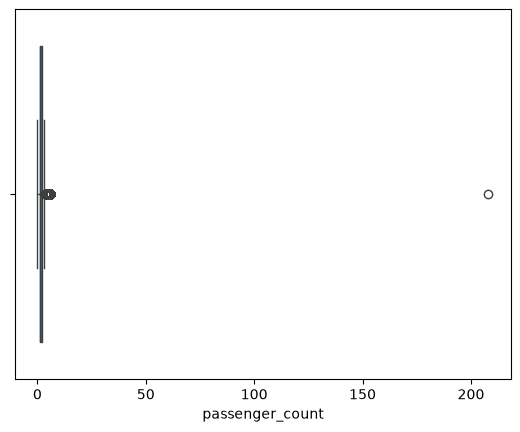

In [231]:
sns.boxplot(x = df['passenger_count'])

<Axes: xlabel='distance'>

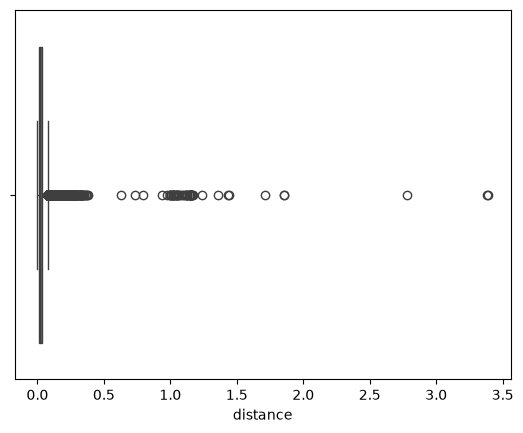

In [232]:
# calculate fare, passenger count and distance


df = df[(df['passenger_count'] > 0) & (df['passenger_count'] < 6)]
df = df[(df['fare_amount'] > 0) & (df['fare_amount'] < 100)]
df = df[(df['distance'] < 5)]
sns.boxplot(x=df['distance'])


<Axes: xlabel='fare_amount'>

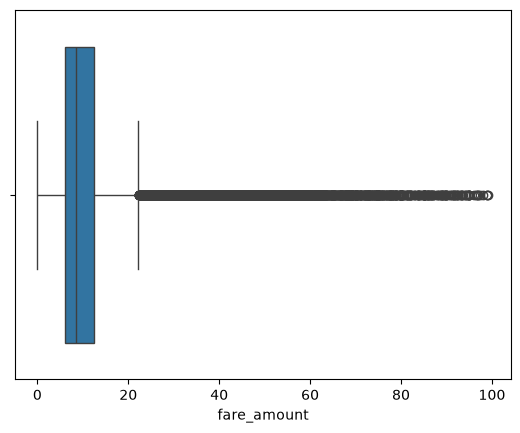

In [233]:
sns.boxplot(x=df['fare_amount'])


<Axes: xlabel='passenger_count'>

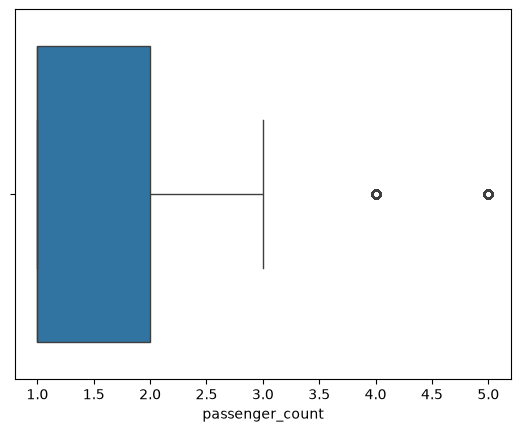

In [234]:
sns.boxplot(x=df['passenger_count'])

In [235]:
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'])

In [236]:
df['hours'] = df['pickup_datetime'].dt.hour
df['hours']

0         19
1         20
2         21
3          8
4         17
          ..
199995    10
199996     1
199997     0
199998    14
199999     4
Name: hours, Length: 194492, dtype: int32

In [237]:
df['day'] = df['pickup_datetime'].dt.day_of_week
df['day']

0         3
1         4
2         0
3         4
4         3
         ..
199995    6
199996    4
199997    0
199998    2
199999    5
Name: day, Length: 194492, dtype: int32

In [238]:
corr = df[['fare_amount', 'passenger_count', 'distance', 'hours', 'day']].corr()

In [239]:
corr

,fare_amount,passenger_count,distance,hours,day
fare_amount,1.000000,0.007122,0.755882,-0.021329,0.005733
passenger_count,0.007122,1.000000,0.005190,0.017144,0.039802
distance,0.755882,0.005190,1.000000,-0.027177,0.011046
hours,-0.021329,0.017144,-0.027177,1.000000,-0.087074
day,0.005733,0.039802,0.011046,-0.087074,1.000000


<Axes: >

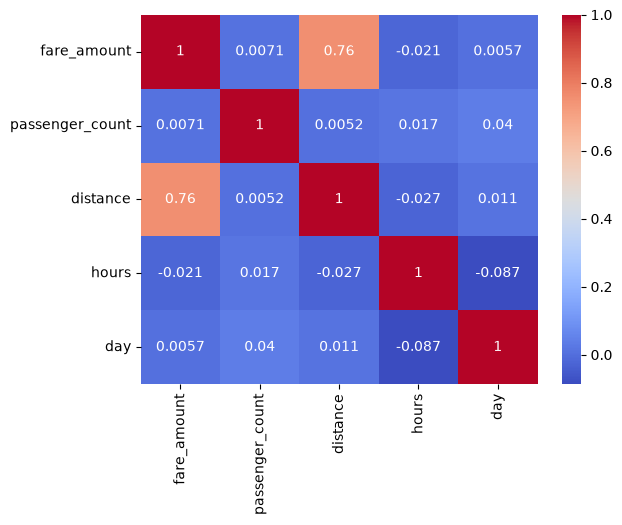

In [240]:
sns.heatmap(corr, annot=True, cmap='coolwarm')

In [241]:
!pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable


In [242]:
from sklearn.model_selection import train_test_split

In [243]:
X = df[['passenger_count', 'distance', 'hours', 'day']]

In [244]:
X

,passenger_count,distance,hours,day
0,1,0.015140,19,3
1,1,0.022103,20,4
2,1,0.053109,21,0
3,3,0.016528,8,4
4,5,0.051031,17,3
...,...,...,...,...
199995,1,0.001064,10,6
199996,1,0.022126,1,4
199997,2,0.142223,0,0
199998,1,0.033101,14,2


In [245]:
Y = df['fare_amount']

In [246]:
Y

0          7.5
1          7.7
2         12.9
3          5.3
4         16.0
          ... 
199995     3.0
199996     7.5
199997    30.9
199998    14.5
199999    14.1
Name: fare_amount, Length: 194492, dtype: float64

In [247]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

In [248]:
X_train

,passenger_count,distance,hours,day
10235,1,0.026340,18,1
194091,1,0.017340,9,2
95997,1,0.022218,17,6
95678,1,0.009634,9,1
56344,1,0.000018,16,3
...,...,...,...,...
123225,1,0.015936,22,2
106575,5,0.025811,22,4
135627,1,0.029488,19,1
150999,1,0.038581,0,4


In [249]:
from sklearn.linear_model import LinearRegression

In [250]:
lr = LinearRegression()

In [251]:
linear_pred = lr.fit(X_train, Y_train)
#trained model

In [252]:
linear_Y = linear_pred.predict(X_test)

In [253]:
from sklearn.metrics import root_mean_squared_error, r2_score

In [254]:
lr_rmse = root_mean_squared_error(Y_test, linear_Y)
lr_rmse

5.936327765462558

In [255]:
r2_lr = r2_score(Y_test, linear_Y)
r2_lr

0.603800301433213

In [256]:
from sklearn.ensemble import RandomForestRegressor

In [257]:
rf = RandomForestRegressor(random_state=42, n_estimators=100)

In [258]:
train_rf = rf.fit(X_train, Y_train)

In [260]:
rf_pred = train_rf.predict(X_test)

In [261]:
rf_pred

array([14.0943,  5.434 ,  9.004 , ...,  8.147 ,  4.042 ,  8.595 ],
      shape=(38899,))

In [262]:
rf_rsme = root_mean_squared_error(Y_test, rf_pred)
rf_rsme

4.597706604848671

In [263]:
rf_r2 = r2_score(Y_test, rf_pred)
rf_r2

0.7623373665183525